# Marketing Campaign EDA — iFood Marketing Campaign Dataset

Phase 7 of the Marketing Intelligence & Campaign Optimization Platform project.

This notebook explores the **cleaned** version of the dataset (built by `scripts/clean_data.py`, Phase 2) and produces the visual analyses referenced throughout `docs/`. Every number and chart here is generated live from the real data — nothing is hard-coded or copied from the docs.

See `docs/07_python_eda_learning.md` for the full Hinglish explanation of every concept and chart used here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

pd.set_option("display.max_columns", 40)

## 1. Load the Cleaned Data & First Look

We load the three processed star-schema tables built in Phase 2 (`scripts/clean_data.py`) and Phase 5 (`scripts/segment_customers.py`, which added the RFM/segment columns onto `dim_customers`). We never touch `data/raw/` here — EDA always runs on the cleaned, analysis-ready data.

In [2]:
dim_customers = pd.read_csv("../data/processed/dim_customers.csv")
fact_campaign = pd.read_csv("../data/processed/fact_campaign_response.csv")
fact_channel = pd.read_csv("../data/processed/fact_channel_purchases.csv")

print("dim_customers:", dim_customers.shape)
print("fact_campaign_response:", fact_campaign.shape)
print("fact_channel_purchases:", fact_channel.shape)

dim_customers.head()

dim_customers: (2212, 29)
fact_campaign_response: (13272, 3)
fact_channel_purchases: (6636, 3)


,customer_id,year_birth,age,education,marital_status,income,kidhome,teenhome,total_children,dt_customer,customer_tenure_days,recency,mnt_wines,mnt_fruits,mnt_meat_products,mnt_fish_products,mnt_sweet_products,mnt_gold_prods,total_spend,num_deals_purchases,num_web_visits_month,total_purchases,num_campaigns_accepted,complain,R_score,F_score,M_score,rfm_score,segment
0,5524,1957,57,Graduation,Single,58138.0,0,0,0,2012-09-04,848,58,635,88,546,172,88,88,1617,3,7,22,1,0,2,4,4,10,Champions
1,2174,1954,60,Graduation,Single,46344.0,1,1,2,2014-03-08,298,38,11,1,6,2,1,6,27,2,5,4,0,0,3,1,1,5,At Risk
2,4141,1965,49,Graduation,Together,71613.0,0,0,0,2013-08-21,497,26,426,49,127,111,21,42,776,1,4,20,0,0,3,4,3,10,Champions
3,6182,1984,30,Graduation,Together,26646.0,1,0,1,2014-02-10,324,26,11,4,20,10,3,5,53,2,6,6,0,0,3,1,1,5,At Risk
4,5324,1981,33,PhD,Married,58293.0,1,0,1,2014-01-19,346,94,173,43,118,46,27,15,422,5,5,14,0,0,1,3,3,7,Loyal Customers


In [3]:
dim_customers.info()
print()
dim_customers[["income", "age", "total_spend", "total_purchases", "recency", "num_campaigns_accepted"]].describe().round(1)

<class 'pandas.DataFrame'>
RangeIndex: 2212 entries, 0 to 2211
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2212 non-null   int64  
 1   year_birth              2212 non-null   int64  
 2   age                     2212 non-null   int64  
 3   education               2212 non-null   str    
 4   marital_status          2212 non-null   str    
 5   income                  2212 non-null   float64
 6   kidhome                 2212 non-null   int64  
 7   teenhome                2212 non-null   int64  
 8   total_children          2212 non-null   int64  
 9   dt_customer             2212 non-null   str    
 10  customer_tenure_days    2212 non-null   int64  
 11  recency                 2212 non-null   int64  
 12  mnt_wines               2212 non-null   int64  
 13  mnt_fruits              2212 non-null   int64  
 14  mnt_meat_products       2212 non-null   int64  
 15

,income,age,total_spend,total_purchases,recency,num_campaigns_accepted
count,2212.0,2212.0,2212.0,2212.0,2212.0,2212.0
mean,51958.8,45.1,607.3,12.6,49.0,0.4
std,21527.3,11.7,602.5,7.2,28.9,0.9
min,1730.0,18.0,5.0,0.0,0.0,0.0
25%,35233.5,37.0,69.0,6.0,24.0,0.0
50%,51371.0,44.0,397.0,12.0,49.0,0.0
75%,68487.0,55.0,1048.0,18.2,74.0,1.0
max,162397.0,74.0,2525.0,32.0,99.0,5.0


## 2. Univariate Analysis — Numeric Distributions

Histograms for the key numeric fields: `income`, `age`, `total_spend`, `recency`, `total_purchases`, `num_campaigns_accepted`. We're looking for shape (normal vs skewed), spread, and obvious outliers — this connects directly to `docs/08_statistics_learning.md` (mean vs median, skewness, std dev).

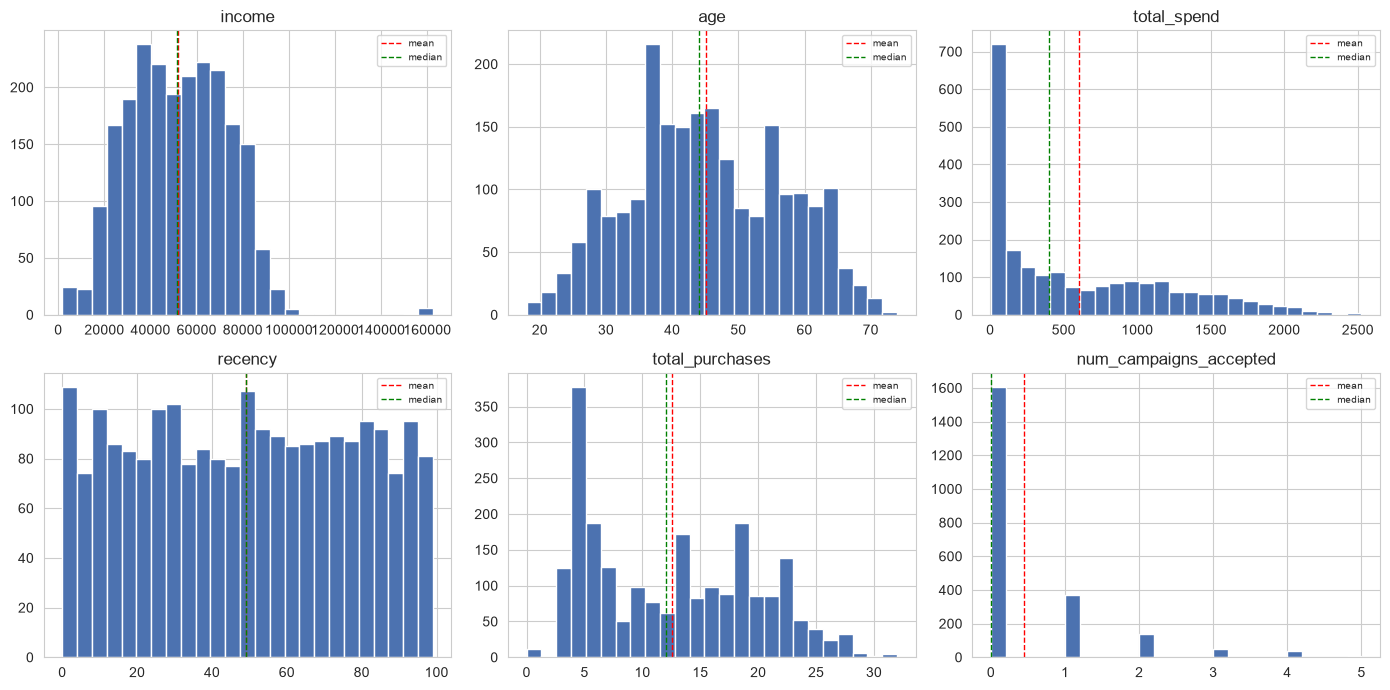

Skew (mean vs median gap check):
  income: mean=51958.8, median=51371.0
  age: mean=45.1, median=44.0
  total_spend: mean=607.3, median=397.0
  recency: mean=49.0, median=49.0
  total_purchases: mean=12.6, median=12.0
  num_campaigns_accepted: mean=0.4, median=0.0


In [4]:
numeric_cols = ["income", "age", "total_spend", "recency", "total_purchases", "num_campaigns_accepted"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), numeric_cols):
    ax.hist(dim_customers[col], bins=25, color="#4C72B0", edgecolor="white")
    ax.axvline(dim_customers[col].mean(), color="red", linestyle="--", linewidth=1, label="mean")
    ax.axvline(dim_customers[col].median(), color="green", linestyle="--", linewidth=1, label="median")
    ax.set_title(col)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

print("Skew (mean vs median gap check):")
for col in numeric_cols:
    print(f"  {col}: mean={dim_customers[col].mean():.1f}, median={dim_customers[col].median():.1f}")

## 3. Univariate Analysis — Categorical Fields

Bar charts for `education`, `marital_status`, and the RFM `segment` (Phase 5) — how many customers fall into each category.

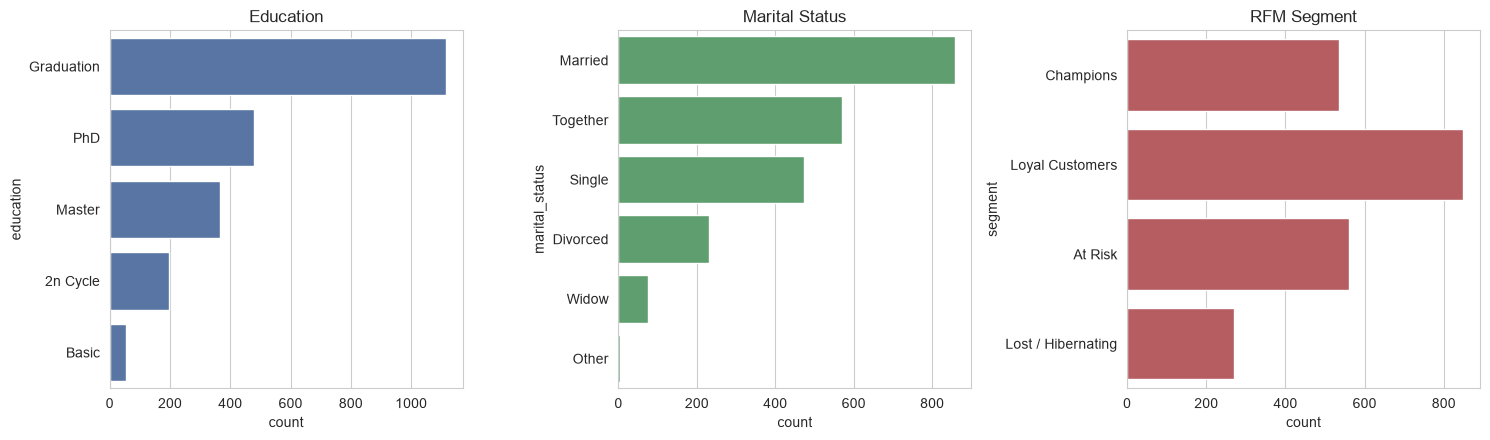

education
Graduation    1115
PhD            480
Master         365
2n Cycle       198
Basic           54
Name: count, dtype: int64 

marital_status
Married     857
Together    571
Single      473
Divorced    231
Widow        76
Other         4
Name: count, dtype: int64 

segment
Loyal Customers       849
At Risk               560
Champions             534
Lost / Hibernating    269
Name: count, dtype: int64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

order1 = dim_customers["education"].value_counts().index
sns.countplot(data=dim_customers, y="education", order=order1, ax=axes[0], color="#4C72B0")
axes[0].set_title("Education")

order2 = dim_customers["marital_status"].value_counts().index
sns.countplot(data=dim_customers, y="marital_status", order=order2, ax=axes[1], color="#55A868")
axes[1].set_title("Marital Status")

order3 = ["Champions", "Loyal Customers", "At Risk", "Lost / Hibernating"]
sns.countplot(data=dim_customers, y="segment", order=order3, ax=axes[2], color="#C44E52")
axes[2].set_title("RFM Segment")

plt.tight_layout()
plt.show()

print(dim_customers["education"].value_counts(), "\n")
print(dim_customers["marital_status"].value_counts(), "\n")
print(dim_customers["segment"].value_counts())

## 4. Campaign Performance & Channel Performance

Two business questions in one row of charts: (1) which of the 6 campaigns had the best/worst acceptance rate, and (2) how do the 3 sales channels (Web/Catalog/Store) compare by purchase volume.

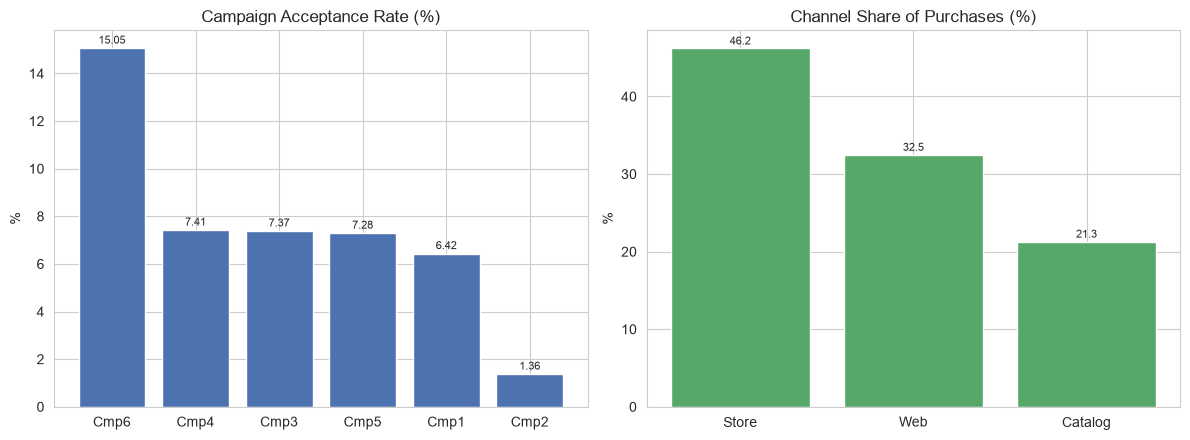

               customers_accepted  customers_targeted  acceptance_rate_pct
campaign_name                                                             
Cmp6                          333                2212                15.05
Cmp4                          164                2212                 7.41
Cmp3                          163                2212                 7.37
Cmp5                          161                2212                 7.28
Cmp1                          142                2212                 6.42
Cmp2                           30                2212                 1.36

         total_purchases  share_pct
channel                            
Store              12844       46.2
Web                 9043       32.5
Catalog             5911       21.3


In [6]:
campaign_summary = (
    fact_campaign.groupby("campaign_name")["accepted"]
    .agg(customers_accepted="sum", customers_targeted="count")
    .assign(acceptance_rate_pct=lambda d: (100 * d["customers_accepted"] / d["customers_targeted"]).round(2))
    .sort_values("acceptance_rate_pct", ascending=False)
)

channel_summary = (
    fact_channel.groupby("channel")["num_purchases"]
    .agg(total_purchases="sum")
    .assign(share_pct=lambda d: (100 * d["total_purchases"] / d["total_purchases"].sum()).round(1))
    .sort_values("total_purchases", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(campaign_summary.index, campaign_summary["acceptance_rate_pct"], color="#4C72B0")
axes[0].set_title("Campaign Acceptance Rate (%)")
axes[0].set_ylabel("%")
for i, v in enumerate(campaign_summary["acceptance_rate_pct"]):
    axes[0].text(i, v + 0.2, str(v), ha="center", fontsize=8)

axes[1].bar(channel_summary.index, channel_summary["share_pct"], color="#55A868")
axes[1].set_title("Channel Share of Purchases (%)")
axes[1].set_ylabel("%")
for i, v in enumerate(channel_summary["share_pct"]):
    axes[1].text(i, v + 0.5, str(v), ha="center", fontsize=8)

plt.tight_layout()
plt.show()

print(campaign_summary)
print()
print(channel_summary)

## 5. Segmentation Deep Dive (RFM segments from Phase 5)

Three views of the same 4 segments: average spend, share of total revenue, and campaign acceptance rate. This is the visual version of the table already computed in `docs/05_customer_segmentation.md`.

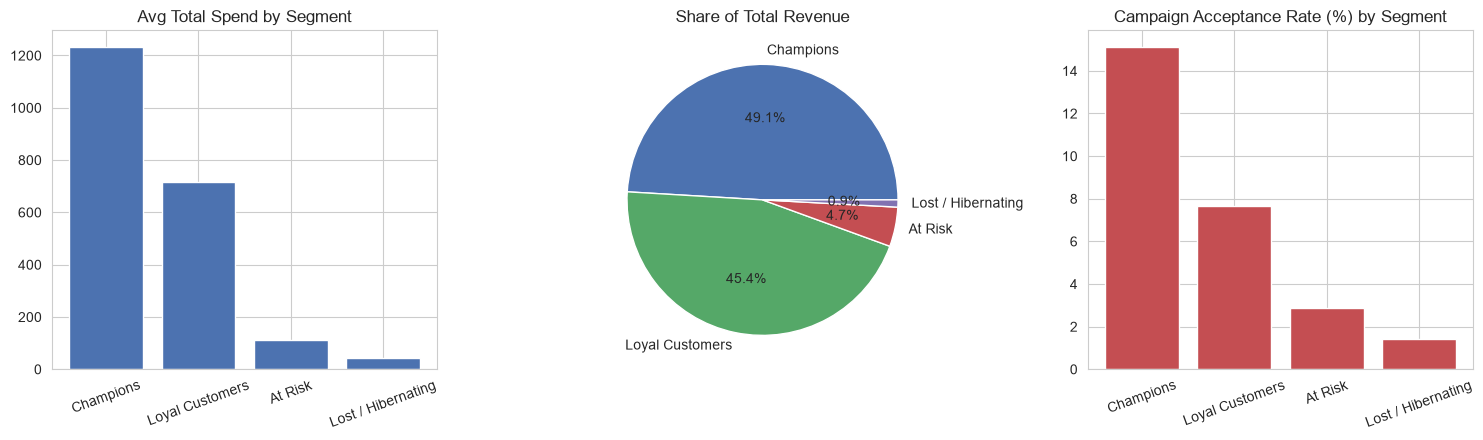

Avg spend:
 segment
Champions             1234.0
Loyal Customers        718.0
At Risk                113.0
Lost / Hibernating      43.0
Name: total_spend, dtype: float64 

Revenue share %:
 segment
Champions             49.1
Loyal Customers       45.4
At Risk                4.7
Lost / Hibernating     0.9
Name: total_spend, dtype: float64 

Acceptance rate %:
 segment
Champions             15.14
Loyal Customers        7.64
At Risk                2.86
Lost / Hibernating     1.43
Name: accepted, dtype: float64


In [7]:
segment_order = ["Champions", "Loyal Customers", "At Risk", "Lost / Hibernating"]

# Merge segment (from dim_customers) onto each campaign-response row so we can
# compute an acceptance rate per segment -- a classic dimension-join-to-fact pattern.
merged = fact_campaign.merge(dim_customers[["customer_id", "segment", "total_spend"]], on="customer_id")

seg_spend = dim_customers.groupby("segment")["total_spend"].mean().reindex(segment_order)
seg_revenue_share = (dim_customers.groupby("segment")["total_spend"].sum() / dim_customers["total_spend"].sum() * 100).reindex(segment_order)
seg_acceptance = (merged.groupby("segment")["accepted"].mean() * 100).reindex(segment_order)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].bar(segment_order, seg_spend, color="#4C72B0")
axes[0].set_title("Avg Total Spend by Segment")
axes[0].tick_params(axis="x", rotation=20)

axes[1].pie(seg_revenue_share, labels=segment_order, autopct="%1.1f%%", colors=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
axes[1].set_title("Share of Total Revenue")

axes[2].bar(segment_order, seg_acceptance, color="#C44E52")
axes[2].set_title("Campaign Acceptance Rate (%) by Segment")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("Avg spend:\n", seg_spend.round(0), "\n")
print("Revenue share %:\n", seg_revenue_share.round(1), "\n")
print("Acceptance rate %:\n", seg_acceptance.round(2))

## 6. Bivariate Analysis — Correlation Heatmap & Income vs. Spend

A correlation heatmap across the key numeric fields, and a scatter plot of `income` vs. `total_spend` colored by segment — checking whether higher income visibly relates to higher spend, and how cleanly the RFM segments separate on this view.

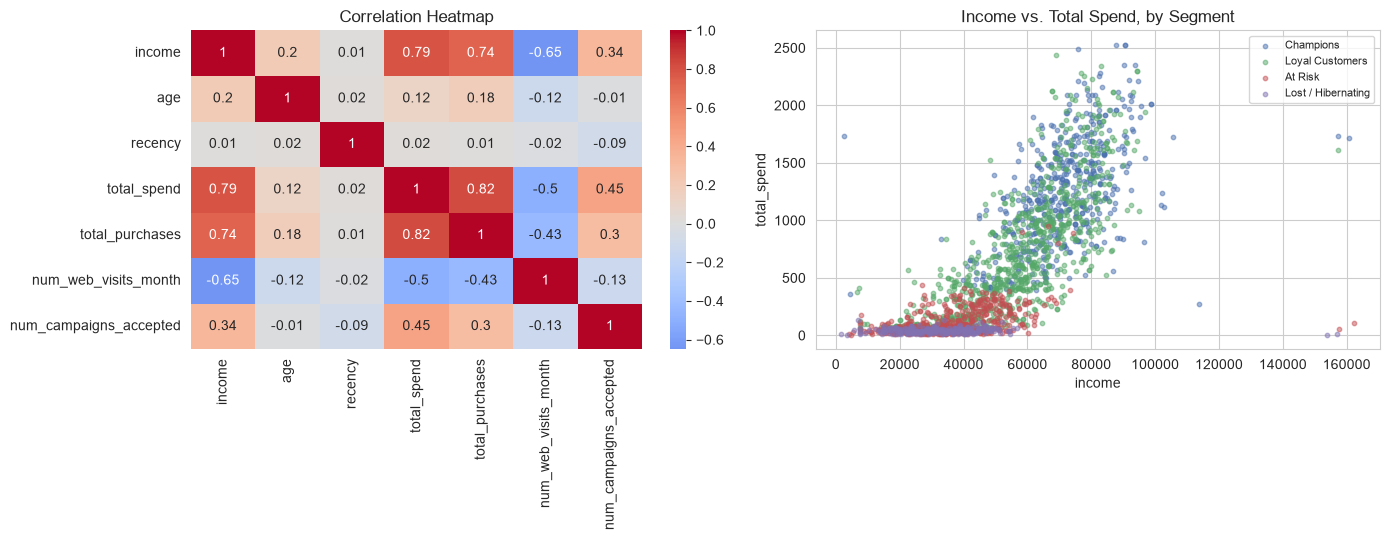

Correlation of income with total_spend: 0.79
Correlation of recency with num_campaigns_accepted: -0.09


In [8]:
corr_cols = ["income", "age", "recency", "total_spend", "total_purchases", "num_web_visits_month", "num_campaigns_accepted"]
corr = dim_customers[corr_cols].corr().round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation Heatmap")

segment_colors = {"Champions": "#4C72B0", "Loyal Customers": "#55A868", "At Risk": "#C44E52", "Lost / Hibernating": "#8172B2"}
for seg, color in segment_colors.items():
    subset = dim_customers[dim_customers["segment"] == seg]
    axes[1].scatter(subset["income"], subset["total_spend"], s=10, alpha=0.5, label=seg, color=color)
axes[1].set_xlabel("income")
axes[1].set_ylabel("total_spend")
axes[1].set_title("Income vs. Total Spend, by Segment")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Correlation of income with total_spend:", corr.loc["income", "total_spend"])
print("Correlation of recency with num_campaigns_accepted:", corr.loc["recency", "num_campaigns_accepted"])

## 7. Funnel Visualization & Outlier Check (Boxplot)

Left: the real 4-stage funnel from `docs/06_funnel_analysis.md`, computed live here (not hard-coded) — Total Customers → Made ≥1 Purchase → Used a Deal → Accepted ≥1 Campaign. Right: a boxplot of `total_spend` by segment, useful for spotting spread and outliers per group.

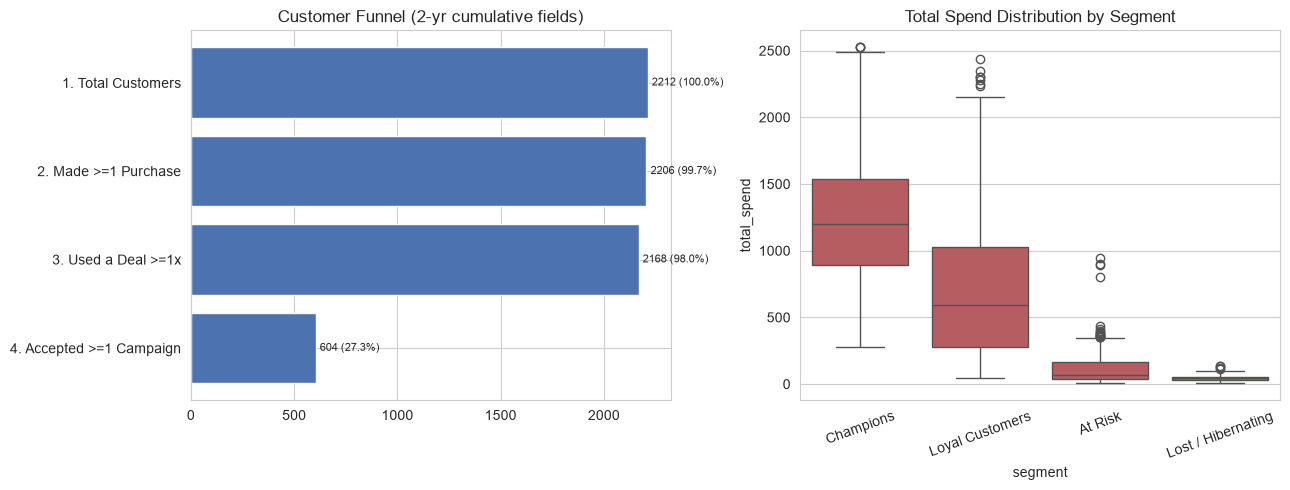

1. Total Customers          2212
2. Made >=1 Purchase        2206
3. Used a Deal >=1x         2168
4. Accepted >=1 Campaign     604
dtype: int64

Stage-to-stage retention %:
1. Total Customers           NaN
2. Made >=1 Purchase        99.7
3. Used a Deal >=1x         98.3
4. Accepted >=1 Campaign    27.9
dtype: float64


In [9]:
funnel_stages = {
    "1. Total Customers": len(dim_customers),
    "2. Made >=1 Purchase": (dim_customers["total_purchases"] >= 1).sum(),
    "3. Used a Deal >=1x": (dim_customers["num_deals_purchases"] >= 1).sum(),
    "4. Accepted >=1 Campaign": (dim_customers["num_campaigns_accepted"] >= 1).sum(),
}
funnel_df = pd.Series(funnel_stages)
funnel_pct = (funnel_df / funnel_df.iloc[0] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(list(funnel_df.index)[::-1], list(funnel_df.values)[::-1], color="#4C72B0")
for i, (val, pct) in enumerate(zip(list(funnel_df.values)[::-1], list(funnel_pct.values)[::-1])):
    axes[0].text(val + 20, i, f"{val} ({pct}%)", va="center", fontsize=8)
axes[0].set_title("Customer Funnel (2-yr cumulative fields)")

sns.boxplot(data=dim_customers, x="segment", y="total_spend", order=segment_order, ax=axes[1], color="#C44E52")
axes[1].set_title("Total Spend Distribution by Segment")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print(funnel_df)
print()
print("Stage-to-stage retention %:")
print((funnel_df / funnel_df.shift(1) * 100).round(1))

## 8. Key Takeaways From This EDA (real, computed above — nothing hard-coded)

- **Distributions:** `income` and `age` are roughly bell-shaped/mildly skewed; `total_spend` and `num_campaigns_accepted` are heavily **right-skewed** (a small group of high spenders/responders pulls the mean above the median — `total_spend` mean 607 vs. median 397).
- **Campaigns:** Cmp6 (15.05%) is the clear best performer, Cmp2 (1.36%) the clear worst — over 10x apart.
- **Channels:** Store (46.2%) > Web (32.5%) > Catalog (21.3%) by purchase volume.
- **Segments:** Champions are only 24.1% of customers but 49.1% of revenue and 15.14% campaign acceptance — vs. Lost/Hibernating at 0.9% of revenue and 1.43% acceptance.
- **Correlation highlights:** `income` ↔ `total_spend` = **0.79** (strong positive); `income` ↔ `num_web_visits_month` = **-0.65** (strong negative — richer customers visit the website less often but spend far more, confirming the pattern first found in `sql/04_funnel_analysis.sql`); `recency` ↔ `num_campaigns_accepted` = only **-0.09** (weak) — a useful reminder that a real, monotonic pattern in *grouped averages* (recency bands in Phase 4 SQL) can still show a weak raw correlation coefficient at the individual level, because acceptance is a noisy 0/1 event for any single customer.
- **Funnel:** 99.7% → 98.0% → 27.3% of total — confirms the single biggest drop-off is "used a deal" → "accepted a targeted campaign," not basic buying behavior.
- **Outliers:** the boxplot shows Champions/Loyal Customers have a wide, high spend range (with a few visible high-end outliers), while At Risk/Lost customers are tightly clustered near zero spend.

Full Hinglish explanation of every concept, chart, and pandas function used in this notebook lives in `docs/07_python_eda_learning.md`.